# Proyecto Final de Minería de Datos, Modelado Predictivo Avanzado y Evaluación (CRISP-DM)
## Dataset: Predicción de Abandono de Clientes de Tarjetas de Crédito (*Credit Card Churn*)

Este notebook implementa la fase de **Ingeniería de Características, Modelamiento, Selección Estadística, Optimización de Hiperparámetros y Empaquetado en Pipeline** siguiendo estrictamente los lineamientos del Proyecto Final:

1. **Carga del Dataset Limpio (`credit_card_churn_limpio.csv`)**
2. **Ingeniería de Características (Creación de Variables de Negocio, Codificación y Transformaciones)**
3. **Partición Estratificada 70% Entrenamiento / 30% Prueba y Balanceo con SMOTE sólo en el 70% de Entrenamiento**
4. **Entrenamiento y Validación Cruzada (10-Fold Stratified CV en el 70%) de 7 Modelos:**
   - **4 Métodos de Aprendizaje Supervisado:** Árbol de Decisión, KNN, Red Neuronal (MLP) y SVM.
   - **3 Métodos de Ensamble:** Random Forest (*Bagging*), XGBoost (*Boosting*) y Stacking (*StackingClassifier*).
5. **Cálculo e Interpretación de 5 Medidas de Calidad (`F1-Score`, `Recall`, `Precision`, `Accuracy`, `ROC-AUC`)**
6. **Selección de los 3 Mejores Modelos mediante Diferencia Estadística Significativa (ANOVA y Prueba Post-Hoc de Tukey HSD)**
7. **Hiperparametrización de los 3 Mejores Modelos con `GridSearchCV` y Optimización Bayesiana (`Optuna`)**
8. **Evaluación Final en el 30% de Prueba y Exportación del `Pipeline` Completo para Despliegue en Streamlit**
9. **Interpretación del Resultado en Prueba, Matriz de Confusión en Términos de Negocio e Importancia de Variables**

---
## 1. Carga del Dataset Limpio e Ingeniería de Características
Partimos del archivo `credit_card_churn_limpio.csv` generado en el Notebook 01 (10,120 registros y 19 columnas).

### Operaciones de Ingeniería de Características Aplicadas:
1. **Codificación de la Variable Objetivo (`Attrition_Flag`)**:
   - `Existing Customer` $\rightarrow 0$ (Cliente retenido)
   - `Attrited Customer` $\rightarrow 1$ (Cliente que abandona / Churn)
2. **Creación de Nuevas Variables de Negocio (Ratios Financieros y de Comportamiento)**:
   - `Avg_Ticket_Size` $= \frac{\text{Total\_Trans\_Amt}}{\text{Total\_Trans\_Ct}}$: Valor promedio por transacción en los últimos 12 meses.
   - `Inactivity_Contact_Ratio` $= \text{Months\_Inactive\_12\_mon} \times \text{Contacts\_Count\_12\_mon}$: Índice compuesto de fricción/inactividad (clientes inactivos que además llaman repetidamente al banco presentan alto riesgo de fuga).
   - `Products_Per_Year` $= \frac{\text{Total\_Relationship\_Count}}{\text{Months\_on\_book} / 12}$: Densidad de vinculación de productos por año de antigüedad.
3. **Transformación y Codificación de Variables**:
   - **Variables Categóricas Ordinales** (`Education_Level`, `Income_Category`, `Card_Category`): Codificación ordinal respetando su jerarquía natural.
   - **Variables Categóricas Nominales** (`Gender`, `Marital_Status`): Codificación *One-Hot Encoding* (`drop='first'`).
   - **Variables Numéricas Continuas y Discretas**: Escalado estándar (`StandardScaler`) integrado dentro del `ColumnTransformer` para evitar fuga de datos durante la validación cruzada.

La preparación completa vive dentro del `Pipeline` y por eso `X` conserva aquí las 18 predictoras crudas. Antes del `ColumnTransformer` el `Pipeline` convierte `Unknown` en `NaN`, imputa las categóricas con la moda mediante `SimpleImputer` y calcula las variables de negocio con `FunctionTransformer`. Las funciones `unknown_to_nan` y `add_engineered_features` están en `churn_features.py` para que el modelo guardado se pueda cargar fuera de este notebook.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
from itertools import combinations
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, cross_val_score
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import optuna
import joblib
import json
import warnings
warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

from churn_features import unknown_to_nan, add_engineered_features

# Carga del dataset limpio
df = pd.read_csv("credit_card_churn_limpio.csv")

X = df.drop(columns=['Attrition_Flag'])
y = (df['Attrition_Flag'] == 'Attrited Customer').astype(int)

engineered_cols = ['Avg_Ticket_Size', 'Inactivity_Contact_Ratio', 'Products_Per_Year']

print(f"Dimensiones de entrada del Pipeline: {X.shape[0]} filas x {X.shape[1]} variables predictoras crudas")
print(f"Variables que crea el Pipeline: {engineered_cols}\n")
print(add_engineered_features(X)[engineered_cols].describe().round(3))

Dimensiones de entrada del Pipeline: 10120 filas x 18 variables predictoras crudas
Variables que crea el Pipeline: ['Avg_Ticket_Size', 'Inactivity_Contact_Ratio', 'Products_Per_Year']

       Avg_Ticket_Size  Inactivity_Contact_Ratio  Products_Per_Year
count        10120.000                 10120.000          10120.000
mean            62.611                     5.782              1.356
std             26.395                     3.808              0.707
min             19.138                     0.000              0.214
25%             47.516                     3.000              0.878
50%             55.799                     6.000              1.297
75%             65.483                     8.000              1.714
max            190.193                    36.000              5.538


C:\Users\naoch\Proyecto final mineria\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


---
## 2. División 70% Entrenamiento / 30% Prueba y Balanceo del 70% con SMOTE

Tal como exige la metodología:
- Se realiza una partición estratificada **70% entrenamiento (`X_train`, `y_train`) y 30% prueba (`X_test`, `y_test`)**.
- **Únicamente el 70% de los datos de entrenamiento se balancea** mediante **SMOTE** (*Synthetic Minority Over-sampling Technique*), manteniendo el 30% de prueba intacto con su distribución real para una evaluación honesta libre de *Data Leakage*.
- Además, durante la validación cruzada sobre el 70%, SMOTE se integra dentro de `ImbPipeline` para que en cada *fold* se sobremuestree exclusivamente el subconjunto de entrenamiento del *fold*.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

ordinal_cols = ['Education_Level', 'Income_Category', 'Card_Category']
ordinal_categories = [
    ['Uneducated', 'High School', 'College', 'Graduate', 'Post-Graduate', 'Doctorate'],
    ['Less than $40K', '$40K - $60K', '$60K - $80K', '$80K - $120K', '$120K +'],
    ['Blue', 'Silver', 'Gold', 'Platinum']
]
nominal_cols = ['Gender', 'Marital_Status']
numeric_cols = [c for c in X.columns if c not in ordinal_cols + nominal_cols] + engineered_cols

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('ord', OrdinalEncoder(categories=ordinal_categories, handle_unknown='use_encoded_value', unknown_value=-1), ordinal_cols),
        ('nom', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), nominal_cols)
    ]
)

# Imputación por moda de las categóricas, las numéricas pasan sin cambios
categorical_imputer = ColumnTransformer(
    transformers=[('cat', SimpleImputer(strategy='most_frequent'), ordinal_cols + nominal_cols)],
    remainder='passthrough',
    verbose_feature_names_out=False
).set_output(transform='pandas')

# Preparación completa, recibe las 18 predictoras crudas
preparation_steps = [
    ('unknown_to_nan', FunctionTransformer(unknown_to_nan)),
    ('imputer', categorical_imputer),
    ('features', FunctionTransformer(add_engineered_features)),
    ('preprocessor', preprocessor)
]
preparation = Pipeline(steps=preparation_steps)

# Balanceo con SMOTE únicamente sobre el 70% de entrenamiento
X_train_prep = preparation.fit_transform(X_train)
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train_prep, y_train)

print(f"Conjunto de Entrenamiento (70%) Antes de SMOTE: {X_train.shape[0]} registros -> {y_train.value_counts().to_dict()}")
print(f"Conjunto de Entrenamiento (70%) Después de SMOTE: {X_train_bal.shape[0]} registros -> {pd.Series(y_train_bal).value_counts().to_dict()}")
print(f"Conjunto de Prueba (30% sin balancear): {X_test.shape[0]} registros -> {y_test.value_counts().to_dict()}")

Conjunto de Entrenamiento (70%) Antes de SMOTE: 7084 registros -> {0: 5946, 1: 1138}
Conjunto de Entrenamiento (70%) Después de SMOTE: 11892 registros -> {0: 5946, 1: 5946}
Conjunto de Prueba (30% sin balancear): 3036 registros -> {0: 2548, 1: 488}


---
## 3. Entrenamiento y Validación Cruzada (70% de los Datos), 7 Modelos

Se configuran y evalúan **7 modelos predictivos** mediante **Validación Cruzada Estratificada de 10 particiones (`StratifiedKFold(n_splits=10)`)** sobre el 70% de los datos:

### A. 4 Métodos de Aprendizaje Supervisado:
1. **Árbol de Decisión (`DecisionTreeClassifier`)**
2. **KNN (`KNeighborsClassifier`)**
3. **Red Neuronal (`MLPClassifier` - Perceptrón Multicapa)**
4. **SVM (`SVC` con kernel RBF)**

### B. 3 Métodos de Ensamble:
5. **Random Forest (`RandomForestClassifier` - Ensamble *Bagging*)**
6. **XGBoost (`XGBClassifier` - Ensamble *Boosting*)**
7. **Stacking (`StackingClassifier` - Meta-modelo con Árbol, Random Forest y XGBoost)**

Para cada modelo se calculan **5 medidas de calidad**: `Accuracy`, `Precision`, `Recall` (Sensibilidad), `F1-Score` y `ROC-AUC`, además del tiempo de entrenamiento.

In [3]:
models = {
    "1. Árbol de Decisión (Supervisado)": DecisionTreeClassifier(max_depth=8, random_state=42),
    "2. KNN (Supervisado)": KNeighborsClassifier(n_neighbors=7),
    "3. Red Neuronal (Supervisado)": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, early_stopping=True, random_state=42),
    "4. SVM (Supervisado)": SVC(kernel='rbf', probability=True, random_state=42),
    "5. Random Forest - Bagging (Ensamble)": RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1),
    "6. XGBoost - Boosting (Ensamble)": XGBClassifier(n_estimators=150, learning_rate=0.1, max_depth=5, random_state=42, eval_metric='logloss', n_jobs=-1),
    "7. Stacking (Ensamble)": StackingClassifier(
        estimators=[
            ('dt', DecisionTreeClassifier(max_depth=8, random_state=42)),
            ('rf', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)),
            ('xgb', XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42, eval_metric='logloss', n_jobs=-1))
        ],
        final_estimator=LogisticRegression(max_iter=1000, random_state=42),
        cv=3,
        n_jobs=1
    )
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

cv_results_dict = {}
summary_rows = []

for name, clf in models.items():
    t0 = time.time()
    pipe = ImbPipeline(steps=preparation_steps + [
        ('smote', SMOTE(random_state=42)),
        ('classifier', clf)
    ])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    elapsed = time.time() - t0
    cv_results_dict[name] = scores
    summary_rows.append({
        "Modelo": name,
        "Accuracy (Media ± DE)": f"{scores['test_accuracy'].mean():.4f} ± {scores['test_accuracy'].std():.4f}",
        "Precision (Media ± DE)": f"{scores['test_precision'].mean():.4f} ± {scores['test_precision'].std():.4f}",
        "Recall (Media ± DE)": f"{scores['test_recall'].mean():.4f} ± {scores['test_recall'].std():.4f}",
        "F1-Score (Media ± DE)": f"{scores['test_f1'].mean():.4f} ± {scores['test_f1'].std():.4f}",
        "ROC-AUC (Media ± DE)": f"{scores['test_roc_auc'].mean():.4f} ± {scores['test_roc_auc'].std():.4f}",
        "F1_mean": scores['test_f1'].mean(),
        "Tiempo (s)": round(elapsed, 2)
    })

df_cv_summary = pd.DataFrame(summary_rows).sort_values(by="F1_mean", ascending=False)
print("=== RESULTADOS DE VALIDACIÓN CRUZADA (10-FOLD CV EN EL 70% DE ENTRENAMIENTO CON SMOTE) ===")
print(df_cv_summary.drop(columns=['F1_mean']).to_string(index=False))

=== RESULTADOS DE VALIDACIÓN CRUZADA (10-FOLD CV EN EL 70% DE ENTRENAMIENTO CON SMOTE) ===
                               Modelo Accuracy (Media ± DE) Precision (Media ± DE) Recall (Media ± DE) F1-Score (Media ± DE) ROC-AUC (Media ± DE)  Tiempo (s)
     6. XGBoost - Boosting (Ensamble)       0.9680 ± 0.0026        0.8952 ± 0.0217     0.9077 ± 0.0193       0.9010 ± 0.0075      0.9923 ± 0.0015        1.73
               7. Stacking (Ensamble)       0.9646 ± 0.0022        0.8901 ± 0.0267     0.8911 ± 0.0269       0.8898 ± 0.0068      0.9901 ± 0.0016       14.06
5. Random Forest - Bagging (Ensamble)       0.9615 ± 0.0044        0.8780 ± 0.0220     0.8840 ± 0.0329       0.8803 ± 0.0152      0.9884 ± 0.0015        3.84
        3. Red Neuronal (Supervisado)       0.9351 ± 0.0068        0.7679 ± 0.0298     0.8568 ± 0.0283       0.8092 ± 0.0182      0.9733 ± 0.0052       11.31
   1. Árbol de Decisión (Supervisado)       0.9328 ± 0.0087        0.7546 ± 0.0387     0.8674 ± 0.0328       0.8060 ± 0

### Interpretación Detallada de las Medidas de Calidad Obtenidas:
1. **`F1-Score` (Media armónica entre Precision y Recall, Métrica Principal de Selección)**:
   - Dado que el abandono bancario es un problema desbalanceado (~16.07% de casos positivos), el `Accuracy` por sí solo puede ser engañoso. El `F1-Score` penaliza tanto los falsos positivos (ofrecer campañas de retención a clientes que no iban a irse) como los falsos negativos (no detectar a un cliente que sí abandona el banco).
   - Los 3 métodos de ensamble dominan claramente la clasificación: **XGBoost (Boosting)** alcanza el mayor `F1-Score` promedio (**0.9010**), seguido por **Stacking** (**0.8898**) y **Random Forest (Bagging)** (**0.8803**). Entre los supervisados individuales destacan la **Red Neuronal** (**0.8092**) y el **Árbol de Decisión** (**0.8060**).
2. **`Recall` / Sensibilidad (Capacidad de Detección de Fuga Real)**:
   - Mide qué proporción de los clientes que realmente abandonan el banco son detectados a tiempo por el modelo. Cada cliente que se va sin ser detectado es una oportunidad de retención perdida, por lo que un `Recall` alto (**90.77%** en XGBoost y **89.11%** en Stacking) es vital para minimizar fugas no detectadas.
3. **`Precision` (Valor Predictivo Positivo)**:
   - Indica qué porcentaje de las alertas de abandono emitidas por el modelo corresponden a clientes que efectivamente iban a cancelar su tarjeta. Métodos basados en distancias o hiperplanos (`KNN` con 55.73% y `SVM` con 69.82%), al entrenarse con datos sintéticos de SMOTE, elevan su sensibilidad pero generan más falsas alarmas, mientras que **XGBoost (89.52%)**, **Stacking (89.01%)** y **Random Forest (87.80%)** mantienen una precisión sobresaliente.
4. **`ROC-AUC` (Área Bajo la Curva ROC)**:
   - Evalúa la capacidad discriminativa global en todos los umbrales de probabilidad. Los 3 métodos de ensamble rozan la perfección (**0.9923** en XGBoost, **0.9901** en Stacking y **0.9884** en Random Forest), seguidos de la **Red Neuronal** (**0.9733**).
5. **`Accuracy` (Exactitud Global)**:
   - Un modelo que predice que ningún cliente abandona ya obtendría **83.93%** por el desbalance de clases, así que el **96.80%** de **XGBoost** se interpreta frente a esa referencia y por eso no se usa como criterio principal.
6. **Tiempo de Entrenamiento**:
   - **XGBoost** completa los 10 *folds* en **1.73 s** frente a **41.44 s** de `SVM`, de modo que el mejor `F1-Score` no exige mayor costo de cómputo. Estas cifras dependen del equipo, y XGBoost usa todos los núcleos mientras `SVM` usa uno solo.

---
## 4. Selección de los 3 Mejores Modelos mediante Diferencia Estadística Significativa (ANOVA y Prueba de Tukey HSD)

Para garantizar que la diferencia de rendimiento entre los 7 modelos no se debe al azar del muestreo en los 10 *folds* de validación cruzada, aplicamos:
1. **Análisis de Varianza de una vía (ANOVA)**:
   - $H_0$: Las medias del `F1-Score` de los 7 modelos son estadísticamente iguales ($\mu_1 = \mu_2 = \dots = \mu_7$).
   - $H_1$: Al menos un modelo presenta un `F1-Score` medio significativamente diferente.
2. **Prueba Post-Hoc de Diferencia Honestamente Significativa de Tukey (Tukey HSD)**:
   - Compara todos los pares de modelos con nivel de significancia $\alpha = 0.05$ para aislar el grupo superior estadísticamente dominante y seleccionar los **3 mejores modelos**.

=== PRUEBA ANOVA DE UNA VÍA SOBRE EL F1-SCORE (10-FOLD CV) ===
Estadístico F = 153.1920
Valor p (p-value) = 1.2757e-35



=== PRUEBA POST-HOC DE TUKEY HSD (alpha = 0.05) ===
                    Multiple Comparison of Means - Tukey HSD, FWER=0.05                     
          group1                     group2           meandiff p-adj   lower   upper  reject
--------------------------------------------------------------------------------------------
      1. Árbol de Decisión                     2. KNN  -0.1241    0.0 -0.1511 -0.0971   True
      1. Árbol de Decisión            3. Red Neuronal   0.0032 0.9998 -0.0238  0.0302  False
      1. Árbol de Decisión                     4. SVM  -0.0259 0.0672 -0.0529   0.001  False
      1. Árbol de Decisión 5. Random Forest - Bagging   0.0743    0.0  0.0473  0.1013   True
      1. Árbol de Decisión      6. XGBoost - Boosting    0.095    0.0   0.068   0.122   True
      1. Árbol de Decisión                7. Stacking   0.0838    0.0  0.0568  0.1108   True
                    2. KNN            3. Red Neuronal   0.1273    0.0  0.1003  0.1543   True
                 

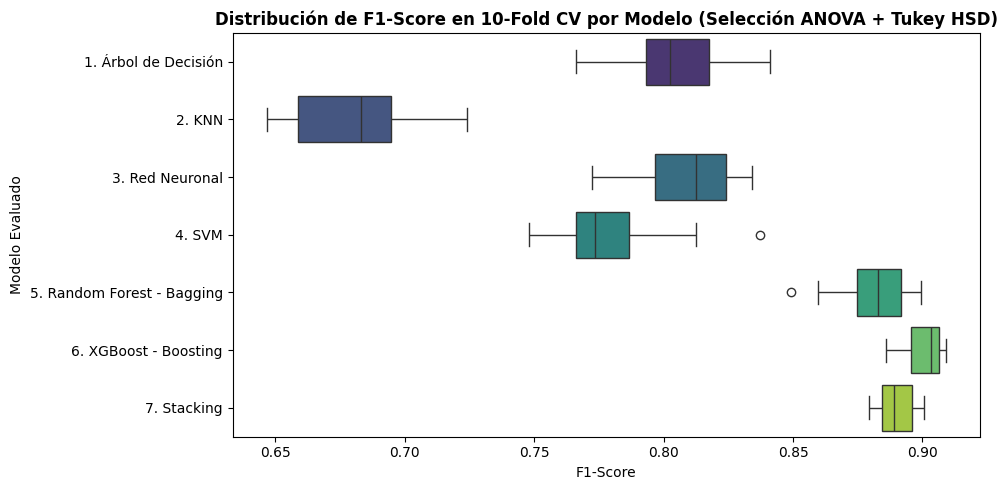

In [4]:
# 1. Prueba ANOVA de una vía sobre los F1-Scores de los 10 Folds
f1_arrays = [scores['test_f1'] for scores in cv_results_dict.values()]
f_stat, p_val_anova = stats.f_oneway(*f1_arrays)

print("=== PRUEBA ANOVA DE UNA VÍA SOBRE EL F1-SCORE (10-FOLD CV) ===")
print(f"Estadístico F = {f_stat:.4f}")
print(f"Valor p (p-value) = {p_val_anova:.4e}")

# 2. Prueba Post-Hoc de Tukey HSD
tukey_records = []
for name, scores in cv_results_dict.items():
    short_name = name.split(" (")[0]
    for val in scores['test_f1']:
        tukey_records.append({"Modelo": short_name, "F1_Score": val})
df_tukey_long = pd.DataFrame(tukey_records)

tukey_res = pairwise_tukeyhsd(endog=df_tukey_long['F1_Score'], groups=df_tukey_long['Modelo'], alpha=0.05)
print("\n=== PRUEBA POST-HOC DE TUKEY HSD (alpha = 0.05) ===")
print(tukey_res.summary())

# p-valores sin el redondeo de la tabla anterior
df_tukey_p = pd.DataFrame(list(combinations(tukey_res.groupsunique, 2)), columns=['Modelo A', 'Modelo B'])
df_tukey_p['Diferencia F1 (B - A)'] = np.round(tukey_res.meandiffs, 4)
df_tukey_p['p-adj'] = tukey_res.pvalues
df_tukey_p['Significativa'] = tukey_res.reject
print("\n=== P-VALORES AJUSTADOS DE TUKEY SIN REDONDEAR ===")
print(df_tukey_p.to_string(index=False, formatters={'p-adj': '{:.3e}'.format}))

# Visualización comparativa de distribuciones de F1-Score
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_tukey_long, x='F1_Score', y='Modelo', palette='viridis')
plt.title("Distribución de F1-Score en 10-Fold CV por Modelo (Selección ANOVA + Tukey HSD)", fontweight='bold')
plt.xlabel("F1-Score")
plt.ylabel("Modelo Evaluado")
plt.tight_layout()
plt.show()

---
## 5. Hiperparametrización de los 3 Mejores Modelos (`GridSearchCV` + Optimización Bayesiana con `Optuna`)

El análisis ANOVA ($F = 153.19$, $p = 1.28 \times 10^{-35} < 0.05$) rechaza la hipótesis nula de igualdad de medias, y la prueba **Tukey HSD** muestra que los **3 métodos de ensamble** superan significativamente a los 4 métodos supervisados. En las 12 comparaciones entre un ensamble y un supervisado el p ajustado más alto es $6.61 \times 10^{-10}$, que corresponde a Random Forest frente a la Red Neuronal. Le siguen Random Forest frente al Árbol de Decisión con $1.54 \times 10^{-10}$, Stacking frente a la Red Neuronal con $9.09 \times 10^{-12}$, Stacking frente al Árbol de Decisión con $2.13 \times 10^{-12}$ y XGBoost frente a la Red Neuronal con $2.71 \times 10^{-14}$. Las siete comparaciones restantes aparecen con p igual a 0 porque quedan por debajo de la precisión numérica del cálculo.

En cambio los 3 ensambles no difieren significativamente entre sí, ya que XGBoost frente a Random Forest da $p = 0.2443$, XGBoost frente a Stacking da $p = 0.8652$ y Random Forest frente a Stacking da $p = 0.9345$. La estadística permite entonces separar al grupo de los ensambles, pero no señala un único ganador dentro de él. Por eso el modelo final se elige por el mayor `F1-Score` medio y el menor tiempo de entrenamiento. XGBoost cumple ambos criterios dentro del grupo, con un `F1-Score` de 0.9010 frente a 0.8898 de Stacking y 0.8803 de Random Forest, y con 1.73 segundos en los 10 folds frente a 14.06 de Stacking y 3.84 de Random Forest.

Por consiguiente, los **3 mejores modelos seleccionados** son:
1. **XGBoost (Boosting)**
2. **Stacking (Ensamble)**
3. **Random Forest (Bagging)**

Estos 3 modelos pasan por un proceso doble de hiperparametrización sobre el conjunto de entrenamiento (70%), siempre con el `Pipeline` completo, los mismos 10 folds de la comparación inicial y el `F1-Score` como criterio. La tabla incluye como línea base el `F1-Score` de la configuración usada en la comparación inicial:
- **Búsqueda en Cuadrícula (`GridSearchCV`)**.
- **Optimización Bayesiana (`Optuna` con algoritmo TPE, *Tree-structured Parzen Estimator*)** maximizando el `F1-Score`.

In [5]:
# Hiperparametrización de los 3 mejores modelos (XGBoost, Stacking y Random Forest)
# sobre el Pipeline completo, con los mismos 10 folds y el scoring F1 de la comparación inicial
def build_pipeline(clf):
    return ImbPipeline(steps=preparation_steps + [
        ('smote', SMOTE(random_state=42)),
        ('classifier', clone(clf))
    ])

def strip_prefix(params):
    return {k.replace('classifier__', '', 1): v for k, v in params.items()}

def run_grid_search(clf, param_grid):
    t0 = time.time()
    gs = GridSearchCV(build_pipeline(clf), param_grid, scoring='f1', cv=cv, refit=False, n_jobs=1, error_score='raise')
    gs.fit(X_train, y_train)
    return float(gs.best_score_), strip_prefix(gs.best_params_), round(time.time() - t0, 2)

def run_optuna(clf, suggest_params, n_trials):
    t0 = time.time()
    def objective(trial):
        pipe = build_pipeline(clf).set_params(**suggest_params(trial))
        return cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1', n_jobs=1, error_score='raise').mean()
    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(objective, n_trials=n_trials)
    best_params = {k: (round(v, 4) if isinstance(v, float) else v) for k, v in strip_prefix(study.best_params).items()}
    return float(study.best_value), best_params, round(time.time() - t0, 2)

def tuning_rows_for(modelo, nombre_cv, base_params, gs_result, opt_result):
    tiempo_base = df_cv_summary.set_index('Modelo').loc[nombre_cv, 'Tiempo (s)']
    filas = [
        ("Línea base (comparación inicial)", cv_results_dict[nombre_cv]['test_f1'].mean(), base_params, tiempo_base),
        ("GridSearchCV", *gs_result),
        ("Optimización Bayesiana (Optuna TPE)", *opt_result)
    ]
    return [{"Modelo": modelo, "Método de Optimización": metodo, "Mejor F1-Score (CV)": round(float(f1), 4),
             "Mejores Hiperparámetros": str(params), "Tiempo (s)": float(tiempo)} for metodo, f1, params, tiempo in filas]

nombre_xgb = "6. XGBoost - Boosting (Ensamble)"
nombre_stk = "7. Stacking (Ensamble)"
nombre_rf = "5. Random Forest - Bagging (Ensamble)"

# 1. XGBoost (GridSearchCV + Optuna), 8 combinaciones y 15 trials
xgb_param_grid = {
    'classifier__n_estimators': [150, 250],
    'classifier__max_depth': [5, 6],
    'classifier__learning_rate': [0.08, 0.1],
    'classifier__subsample': [0.85]
}
def suggest_xgb(trial):
    return {
        'classifier__n_estimators': trial.suggest_int('classifier__n_estimators', 150, 300, step=50),
        'classifier__max_depth': trial.suggest_int('classifier__max_depth', 4, 7),
        'classifier__learning_rate': round(trial.suggest_float('classifier__learning_rate', 0.05, 0.15), 4),
        'classifier__subsample': round(trial.suggest_float('classifier__subsample', 0.75, 0.95), 4),
        'classifier__colsample_bytree': round(trial.suggest_float('classifier__colsample_bytree', 0.70, 0.95), 4)
    }
xgb_base_params = {'n_estimators': 150, 'max_depth': 5, 'learning_rate': 0.1}
best_xgb_gs_score, best_xgb_gs_params, t_xgb_gs = run_grid_search(models[nombre_xgb], xgb_param_grid)
best_xgb_opt_score, best_xgb_opt_params, t_xgb_opt = run_optuna(models[nombre_xgb], suggest_xgb, n_trials=15)

# 2. Stacking (GridSearchCV + Optuna), 4 combinaciones y 8 trials
stk_param_grid = {
    'classifier__final_estimator__C': [0.5, 1.0],
    'classifier__xgb__max_depth': [5, 6]
}
def suggest_stk(trial):
    return {
        'classifier__final_estimator__C': round(trial.suggest_float('classifier__final_estimator__C', 0.2, 3.0), 4),
        'classifier__rf__n_estimators': trial.suggest_int('classifier__rf__n_estimators', 100, 200, step=50),
        'classifier__xgb__max_depth': trial.suggest_int('classifier__xgb__max_depth', 4, 6)
    }
stk_base_params = {'final_estimator__C': 1.0, 'rf__n_estimators': 100, 'xgb__max_depth': 5}
stk_gs_result = run_grid_search(models[nombre_stk], stk_param_grid)
stk_opt_result = run_optuna(models[nombre_stk], suggest_stk, n_trials=8)

# 3. Random Forest (GridSearchCV + Optuna), 8 combinaciones y 15 trials
rf_param_grid = {
    'classifier__n_estimators': [150, 250],
    'classifier__max_depth': [15, None],
    'classifier__min_samples_split': [2, 4]
}
def suggest_rf(trial):
    return {
        'classifier__n_estimators': trial.suggest_int('classifier__n_estimators', 150, 300, step=50),
        'classifier__max_depth': trial.suggest_int('classifier__max_depth', 12, 24),
        'classifier__min_samples_split': trial.suggest_int('classifier__min_samples_split', 2, 6),
        'classifier__min_samples_leaf': trial.suggest_int('classifier__min_samples_leaf', 1, 3)
    }
rf_base_params = {'n_estimators': 150, 'max_depth': None, 'min_samples_split': 2}
rf_gs_result = run_grid_search(models[nombre_rf], rf_param_grid)
rf_opt_result = run_optuna(models[nombre_rf], suggest_rf, n_trials=15)

tuning_rows = (
    tuning_rows_for("XGBoost (Boosting)", nombre_xgb, xgb_base_params, (best_xgb_gs_score, best_xgb_gs_params, t_xgb_gs), (best_xgb_opt_score, best_xgb_opt_params, t_xgb_opt))
    + tuning_rows_for("Stacking (Ensamble)", nombre_stk, stk_base_params, stk_gs_result, stk_opt_result)
    + tuning_rows_for("Random Forest (Bagging)", nombre_rf, rf_base_params, rf_gs_result, rf_opt_result)
)

df_tuning = pd.DataFrame(tuning_rows).sort_values(by="Mejor F1-Score (CV)", ascending=False)
print("=== COMPARATIVA DE HIPERPARAMETRIZACIÓN (LÍNEA BASE VS GRIDSEARCHCV VS OPTUNA, 10-FOLD CV) ===")
print(df_tuning.to_string(index=False))

=== COMPARATIVA DE HIPERPARAMETRIZACIÓN (LÍNEA BASE VS GRIDSEARCHCV VS OPTUNA, 10-FOLD CV) ===
                 Modelo              Método de Optimización  Mejor F1-Score (CV)                                                                                         Mejores Hiperparámetros  Tiempo (s)
     XGBoost (Boosting) Optimización Bayesiana (Optuna TPE)               0.9129 {'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.1266, 'subsample': 0.9278, 'colsample_bytree': 0.7052}       32.66
     XGBoost (Boosting)                        GridSearchCV               0.9100                                  {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 250, 'subsample': 0.85}       17.36
     XGBoost (Boosting)    Línea base (comparación inicial)               0.9010                                                     {'n_estimators': 150, 'max_depth': 5, 'learning_rate': 0.1}        1.73
    Stacking (Ensamble)                        GridSearchCV               0.8936     

---
## 6. Construcción del `Pipeline` Final, Evaluación en el 30% de Prueba y Almacenamiento para Despliegue

El mejor modelo global resultante tras la hiperparametrización es **XGBoost optimizado con Optuna**, que sube de 0.9010 en la línea base a 0.9129 en validación cruzada y también supera a sus alternativas, con 0.9100 en `GridSearchCV`, 0.8936 en el mejor Stacking y 0.8807 en el mejor Random Forest. Este modelo se empaqueta en un **`Pipeline` completo** que integra:
1. Preprocesamiento automático (conversión de `Unknown` a `NaN`, imputación por moda de las categóricas con `SimpleImputer`, ingeniería de características con `FunctionTransformer` y `ColumnTransformer`: `StandardScaler` para numéricas, `OrdinalEncoder` para ordinales y `OneHotEncoder` para nominales).
2. Balanceo con `SMOTE` (activo únicamente durante `.fit()` en el entrenamiento y transparente durante `.predict()` en producción).
3. Clasificador `XGBClassifier` con los hiperparámetros óptimos encontrados.

Se evalúa el `Pipeline` sobre el **30% de datos de prueba (`X_test`, `y_test`)** y se exporta en `modelo_churn_pipeline.joblib` para su uso directo en la interfaz gráfica de **Streamlit**.

=== EVALUACIÓN FINAL EN EL CONJUNTO DE PRUEBA (30%) ===
Accuracy  : 0.9657
Precision : 0.9000
Recall    : 0.8852
F1-Score  : 0.8926
ROC-AUC   : 0.9912

                       precision    recall  f1-score   support

Existing Customer (0)       0.98      0.98      0.98      2548
Attrited Customer (1)       0.90      0.89      0.89       488

             accuracy                           0.97      3036
            macro avg       0.94      0.93      0.94      3036
         weighted avg       0.97      0.97      0.97      3036

Pipeline exportado exitosamente en: modelo_churn_pipeline.joblib
Resultados exportados exitosamente en: resultados_modelado.json


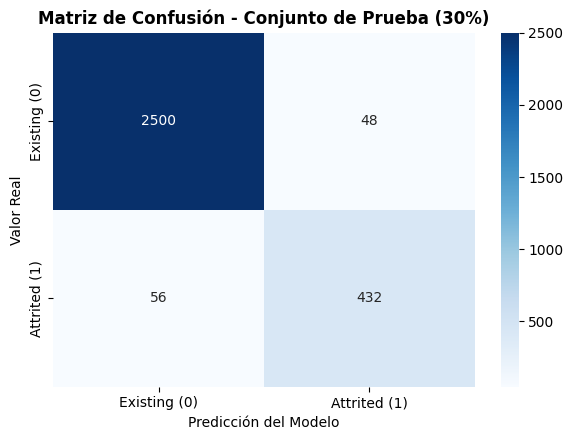

In [6]:
# Selección automática de los mejores hiperparámetros del modelo ganador (XGBoost)
candidatos_xgb = [
    ("Optimización Bayesiana (Optuna TPE)", best_xgb_opt_score, best_xgb_opt_params),
    ("GridSearchCV", best_xgb_gs_score, best_xgb_gs_params),
    ("Línea base (comparación inicial)", cv_results_dict[nombre_xgb]['test_f1'].mean(), xgb_base_params)
]
winning_opt_method, winning_cv_f1, winning_xgb_params = max(candidatos_xgb, key=lambda c: c[1])

final_xgb = XGBClassifier(**winning_xgb_params, random_state=42, eval_metric='logloss', n_jobs=-1)

final_pipeline = build_pipeline(final_xgb)

final_pipeline.fit(X_train, y_train)

# Evaluación sobre el 30% de prueba (datos intactos)
y_pred_test = final_pipeline.predict(X_test)
y_prob_test = final_pipeline.predict_proba(X_test)[:, 1]

test_metrics = {
    "Accuracy": round(float(accuracy_score(y_test, y_pred_test)), 4),
    "Precision": round(float(precision_score(y_test, y_pred_test)), 4),
    "Recall": round(float(recall_score(y_test, y_pred_test)), 4),
    "F1-Score": round(float(f1_score(y_test, y_pred_test)), 4),
    "ROC-AUC": round(float(roc_auc_score(y_test, y_prob_test)), 4)
}

print("=== EVALUACIÓN FINAL EN EL CONJUNTO DE PRUEBA (30%) ===")
print(f"Accuracy  : {test_metrics['Accuracy']:.4f}")
print(f"Precision : {test_metrics['Precision']:.4f}")
print(f"Recall    : {test_metrics['Recall']:.4f}")
print(f"F1-Score  : {test_metrics['F1-Score']:.4f}")
print(f"ROC-AUC   : {test_metrics['ROC-AUC']:.4f}\n")
print(classification_report(y_test, y_pred_test, target_names=['Existing Customer (0)', 'Attrited Customer (1)']))

# Almacenamiento del Pipeline para despliegue en Streamlit
raw_columns = [c for c in df.columns if c != 'Attrition_Flag']
model_bundle = {
    "pipeline": final_pipeline,
    "best_params": winning_xgb_params,
    "optimization_method": winning_opt_method,
    "test_metrics": test_metrics,
    "raw_columns": raw_columns
}
joblib.dump(model_bundle, "modelo_churn_pipeline.joblib")
print("Pipeline exportado exitosamente en: modelo_churn_pipeline.joblib")

# Resultados del modelado para el informe
resultados = {
    "cv_summary": df_cv_summary.drop(columns=['F1_mean']).to_dict(orient='records'),
    "anova_f": round(float(f_stat), 4),
    "anova_p": f"{p_val_anova:.4e}",
    "tukey": [{**fila, "p-adj": float(f"{fila['p-adj']:.4e}"), "Significativa": bool(fila['Significativa'])} for fila in df_tukey_p.to_dict(orient='records')],
    "tuning": df_tuning.to_dict(orient='records'),
    "best_params": winning_xgb_params,
    "test_metrics": test_metrics
}
with open("resultados_modelado.json", "w", encoding="utf-8") as f:
    json.dump(resultados, f, ensure_ascii=False, indent=2)
print("Resultados exportados exitosamente en: resultados_modelado.json")

# Matriz de confusión en el 30% de prueba
cm = confusion_matrix(y_test, y_pred_test)
plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Existing (0)', 'Attrited (1)'],
            yticklabels=['Existing (0)', 'Attrited (1)'])
plt.title("Matriz de Confusión - Conjunto de Prueba (30%)", fontweight='bold')
plt.xlabel("Predicción del Modelo")
plt.ylabel("Valor Real")
plt.tight_layout()
plt.show()

### Reproducibilidad del tuning de XGBoost
Los resultados del tuning de XGBoost pueden variar ligeramente entre computadores, porque con `n_jobs=-1` el muestreo de `subsample`, que se combina con `colsample_bytree` en los hiperparámetros evaluados, depende del número de núcleos. El `Pipeline` guardado en `modelo_churn_pipeline.joblib` es el que reproduce exactamente las métricas reportadas en el 30% de prueba, siempre que se cargue con las versiones de `requirements.txt`.

---
## 7. Prueba del `Pipeline` Guardado con Datos Crudos que Contienen `Unknown`

El modelo anterior fallaba con `Found unknown categories ['Unknown']` al recibir filas del archivo original. Esta celda carga el `Pipeline` desde el archivo guardado y le pasa 5 filas de `credit_card_churn.csv` que tienen `Unknown` en `Education_Level`, `Marital_Status` o `Income_Category`, usando solo las 18 predictoras registradas. Además comprueba que cada `Unknown` llegue al `ColumnTransformer` convertido en la moda aprendida, de modo que el código `-1` del `OrdinalEncoder` no esté ocultando un valor sin imputar. La prueba valida el funcionamiento y no el desempeño, porque estas filas pueden pertenecer al conjunto de entrenamiento.

In [7]:
bundle_cargado = joblib.load("modelo_churn_pipeline.joblib")
pipeline_cargado = bundle_cargado["pipeline"]
columnas_crudas = bundle_cargado["raw_columns"]

df_original = pd.read_csv("credit_card_churn.csv")
columnas_unknown = ['Education_Level', 'Marital_Status', 'Income_Category']
filas_unknown = pd.concat([df_original[df_original[c] == 'Unknown'].head(2) for c in columnas_unknown]).drop_duplicates().head(5)
X_unknown = filas_unknown[columnas_crudas]

preds_unknown = pipeline_cargado.predict(X_unknown)
probs_unknown = pipeline_cargado.predict_proba(X_unknown)[:, 1]

# Los tres primeros pasos deben dejar la moda en lugar de cada Unknown
X_imputado = pipeline_cargado[:3].transform(X_unknown)
modas = dict(zip(ordinal_cols + nominal_cols, pipeline_cargado.named_steps['imputer'].named_transformers_['cat'].statistics_))
X_con_moda = X_unknown.copy()
for c in columnas_unknown:
    X_con_moda[c] = X_con_moda[c].replace('Unknown', modas[c])

assert len(X_unknown) == 5 and X_unknown.shape[1] == 18
assert all((X_unknown[c] == 'Unknown').any() for c in columnas_unknown)
assert not X_imputado.isna().any().any() and not (X_imputado == 'Unknown').any().any()
assert (X_imputado[columnas_unknown].values == X_con_moda[columnas_unknown].values).all()
assert np.array_equal(probs_unknown, pipeline_cargado.predict_proba(X_con_moda)[:, 1])

res_unknown = filas_unknown[columnas_unknown + ['Attrition_Flag']].copy()
res_unknown["Predicción"] = preds_unknown
res_unknown["Probabilidad_Churn"] = np.round(probs_unknown, 4)
print(f"Modas aprendidas: {modas}\n")
print("=== PRUEBA DEL PIPELINE GUARDADO CON 5 FILAS CRUDAS CON Unknown ===")
print(res_unknown.to_string())

Modas aprendidas: {'Education_Level': 'Graduate', 'Income_Category': 'Less than $40K', 'Card_Category': 'Blue', 'Gender': 'F', 'Marital_Status': 'Married'}

=== PRUEBA DEL PIPELINE GUARDADO CON 5 FILAS CRUDAS CON Unknown ===
   Education_Level Marital_Status Income_Category     Attrition_Flag  Predicción  Probabilidad_Churn
6          Unknown        Married         $120K +  Existing Customer           0              0.0005
11         Unknown        Married     $40K - $60K  Existing Customer           0              0.0000
3      High School        Unknown  Less than $40K  Existing Customer           0              0.0002
7      High School        Unknown     $60K - $80K  Existing Customer           0              0.0000
19        Graduate        Married         Unknown  Existing Customer           0              0.0001


---
## 8. Interpretación del Resultado en Prueba, Impacto de Negocio e Importancia de Variables

Esta celda compara el `Pipeline` final en validación cruzada con su resultado en el 30% de prueba, traduce la matriz de confusión a clientes y mide la importancia de variables de dos maneras. La importancia por ganancia sale del propio `XGBClassifier`, y se agrupan las columnas `One-Hot` de una misma variable. La importancia por permutación mide cuánto cae el `F1-Score` en prueba al desordenar cada una de las 18 predictoras crudas.

In [8]:
# Validación cruzada del Pipeline final frente al 30% de prueba
final_cv = cross_validate(final_pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
metricas_cv = {'Accuracy': 'test_accuracy', 'Precision': 'test_precision', 'Recall': 'test_recall', 'F1-Score': 'test_f1', 'ROC-AUC': 'test_roc_auc'}
df_cv_vs_test = pd.DataFrame([
    {"Métrica": m, "CV media (70%)": round(float(final_cv[k].mean()), 4), "CV DE": round(float(final_cv[k].std()), 4),
     "Prueba (30%)": test_metrics[m], "Prueba - CV": round(test_metrics[m] - float(final_cv[k].mean()), 4)}
    for m, k in metricas_cv.items()
])
print("=== PIPELINE FINAL: VALIDACIÓN CRUZADA VS PRUEBA ===")
print(df_cv_vs_test.to_string(index=False))

# Matriz de confusión en términos de clientes
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_test).ravel()
print("\n=== MATRIZ DE CONFUSIÓN EN TÉRMINOS DE NEGOCIO (30% DE PRUEBA) ===")
print(f"Clientes que se fueron: {tp + fn}, detectados: {tp} ({tp / (tp + fn):.2%}), no detectados: {fn}")
print(f"Alertas emitidas: {tp + fp}, acertadas: {tp}, falsas alarmas: {fp} ({fp / (tp + fp):.2%} de las alertas)")
print(f"Clientes que se quedaron: {tn + fp}, sin alerta: {tn}, con falsa alarma: {fp} ({fp / (tn + fp):.2%})")

# Importancia por ganancia, agrupando las columnas One-Hot por variable
nombres_salida = final_pipeline.named_steps['preprocessor'].get_feature_names_out()
def variable_original(nombre):
    nombre = nombre.split('__', 1)[1]
    return next((c for c in nominal_cols if nombre.startswith(c + '_')), nombre)
importancia_ganancia = pd.Series(
    final_pipeline.named_steps['classifier'].feature_importances_,
    index=[variable_original(n) for n in nombres_salida]
).groupby(level=0).sum()

# Importancia por permutación de las 18 predictoras crudas en el 30% de prueba
perm = permutation_importance(final_pipeline, X_test, y_test, scoring='f1', n_repeats=10, random_state=42, n_jobs=1)
importancia_perm = pd.DataFrame({
    'Caída F1 (permutación)': perm.importances_mean,
    'DE': perm.importances_std
}, index=X_test.columns)

df_importancia = pd.DataFrame({'Ganancia (suma 1)': importancia_ganancia}).join(importancia_perm, how='outer')
df_importancia = df_importancia.sort_values('Ganancia (suma 1)', ascending=False).round(4)
df_importancia.index.name = 'Variable'
print("\n=== IMPORTANCIA DE VARIABLES DEL MODELO FINAL ===")
print(df_importancia.to_string(na_rep='calculada'))

resultados.update({
    "final_cv_vs_test": df_cv_vs_test.to_dict(orient='records'),
    "confusion_matrix": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
    "feature_importance": df_importancia.reset_index().astype(object).where(df_importancia.reset_index().notna(), None).to_dict(orient='records')
})
with open("resultados_modelado.json", "w", encoding="utf-8") as f:
    json.dump(resultados, f, ensure_ascii=False, indent=2)
print("\nResultados actualizados en: resultados_modelado.json")

=== PIPELINE FINAL: VALIDACIÓN CRUZADA VS PRUEBA ===
  Métrica  CV media (70%)  CV DE  Prueba (30%)  Prueba - CV
 Accuracy          0.9723 0.0034        0.9657      -0.0066
Precision          0.9226 0.0159        0.9000      -0.0226
   Recall          0.9042 0.0267        0.8852      -0.0190
 F1-Score          0.9129 0.0120        0.8926      -0.0203
  ROC-AUC          0.9932 0.0019        0.9912      -0.0020

=== MATRIZ DE CONFUSIÓN EN TÉRMINOS DE NEGOCIO (30% DE PRUEBA) ===
Clientes que se fueron: 488, detectados: 432 (88.52%), no detectados: 56
Alertas emitidas: 480, acertadas: 432, falsas alarmas: 48 (10.00% de las alertas)
Clientes que se quedaron: 2548, sin alerta: 2500, con falsa alarma: 48 (1.88%)



=== IMPORTANCIA DE VARIABLES DEL MODELO FINAL ===
                          Ganancia (suma 1)  Caída F1 (permutación)        DE
Variable                                                                     
Total_Trans_Ct                       0.2186                  0.4943    0.0122
Total_Revolving_Bal                  0.1055                  0.0423    0.0072
Avg_Ticket_Size                      0.0942               calculada calculada
Total_Relationship_Count             0.0809                  0.0560    0.0066
Total_Trans_Amt                      0.0797                  0.2660    0.0110
Marital_Status                       0.0544                 -0.0016    0.0032
Inactivity_Contact_Ratio             0.0477               calculada calculada
Months_Inactive_12_mon               0.0445                  0.0166    0.0054
Total_Ct_Chng_Q4_Q1                  0.0429                  0.0270    0.0071
Gender                               0.0363                  0.0040    0.0024
Contacts_Coun

### Interpretación del resultado en prueba
El `Pipeline` final obtiene en el 30% de prueba un `F1-Score` de 0.8926, frente a 0.9129 en validación cruzada. La diferencia de 0.0203 equivale a cerca de 1.7 desviaciones estándar entre folds, y todas las métricas bajan en la misma dirección, con 0.0226 menos en `Precision`, 0.0190 menos en `Recall`, 0.0066 menos en `Accuracy` y 0.0020 menos en `ROC-AUC`. La caída es esperable en parte porque los hiperparámetros se escogieron con estos mismos 10 folds, lo que hace algo optimista la cifra de validación cruzada, mientras que el 30% de prueba no intervino en ninguna decisión. Por eso 0.8926 es la estimación que debe reportarse como desempeño esperado. La brecha es moderada y el `ROC-AUC` casi no cambia, de modo que no hay señales de un sobreajuste grave.

### La matriz de confusión en términos de negocio
De los 488 clientes de prueba que realmente abandonaron, el modelo detecta 432, es decir el 88.52%, y deja escapar 56. Emite 480 alertas en total, de las cuales 48 son falsas alarmas, así que 9 de cada 10 alertas apuntan a un cliente que sí se iba. Esas 48 falsas alarmas equivalen al 1.88% de los 2548 clientes que se quedaron, por lo que una campaña de retención dirigida con este modelo rara vez molestaría a un cliente estable. El error con más consecuencias son los 56 clientes no detectados, porque el banco no tendría ocasión de actuar sobre ellos. El proyecto no dispone de los costos de retención ni del valor de cada cliente, así que estos resultados se expresan en clientes y no en dinero.

### Importancia de variables
Las dos medidas coinciden en que el comportamiento transaccional domina el modelo. `Total_Trans_Ct` es la variable más importante, con una ganancia de 0.2186 y una caída de 0.4943 en el `F1-Score` al permutarla, seguida en permutación por `Total_Trans_Amt` con 0.2660, `Total_Relationship_Count` con 0.0560 y `Total_Revolving_Bal` con 0.0423. La permutación de una predictora cruda también altera las variables de ingeniería que dependen de ella, por lo que estas cifras recogen además el aporte de `Avg_Ticket_Size`, `Inactivity_Contact_Ratio` y `Products_Per_Year`, y por esa razón esas tres variables no tienen una caída propia en la tabla.

`Marital_Status` y `Card_Category` salieron no significativas con chi cuadrado en el Notebook 01 ($p = 0.139$ y $p = 0.525$), y la permutación confirma ese resultado, porque desordenarlas casi no cambia el `F1-Score` en prueba, con una caída de $-0.0016 \pm 0.0032$ en `Marital_Status` y de $0.0002 \pm 0.0007$ en `Card_Category`. Ambas cifras son compatibles con un aporte nulo. `Card_Category` también queda baja en ganancia con 0.0120. `Marital_Status` en cambio aparece sexta en ganancia con 0.0544, pero ese valor no refleja capacidad predictiva real. La ganancia suma sus dos columnas `One-Hot` y se mide sobre los datos balanceados con `SMOTE`, que al interpolar crea valores intermedios en esas columnas y probablemente le ofrece a los árboles divisiones sin significado real. Por eso la permutación sobre datos reales es la medida más confiable para esta conclusión.

La significancia del chi cuadrado tampoco garantiza aporte dentro del modelo, porque `Education_Level` e `Income_Category` sí fueron significativas en el Notebook 01 y aun así su caída por permutación es prácticamente nula, con $0.0001 \pm 0.0038$ y $-0.0014 \pm 0.0026$. Esto es coherente con la asociación muy débil que ya mostraba la V de Cramér. Todas estas variables se conservan porque forman parte de las 18 predictoras registradas, y su presencia no impide que el modelo alcance el desempeño reportado.